# 📉 Customer Churn — EDA & Modelling

Exploratory notebook for the churn predictor. The reproducible pipeline lives
in [`src/train.py`](../src/train.py); this notebook shows the reasoning
behind it.

**Outline**

1. Load the data and explore it
2. Choose the features (and drop the leaky ones)
3. Build the preprocessing pipeline
4. Compare models with cross-validation
5. Calibrate the score into a real probability
6. Pick the operating point
7. Evaluate on the test split — **once**
8. Explain the model with SHAP

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Make the notebook runnable from the repository root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from predictor import apply_calibrator, driver_path, explain, feature_labels, logit

DATA = ROOT / "data"
SEED = 42
np.random.seed(SEED)

C:\Users\Risis\AppData\Local\Temp\opencode\churnvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and explore

In [2]:
df = pd.read_excel(DATA / "telco_churn.xlsx")
df.to_csv(DATA / "telco_churn.csv", index=False)
df.shape

(7043, 33)

In [3]:
df.columns = df.columns.str.strip().str.replace(" ", "_")
df.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip_Code               int64
Lat_Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior_Citizen           str
Partner                  str
Dependents               str
Tenure_Months          int64
Phone_Service            str
Multiple_Lines           str
Internet_Service         str
Online_Security          str
Online_Backup            str
Device_Protection        str
Tech_Support             str
Streaming_TV             str
Streaming_Movies         str
Contract                 str
Paperless_Billing        str
Payment_Method           str
Monthly_Charges      float64
Total_Charges         object
Churn_Label              str
Churn_Value            int64
Churn_Score            int64
CLTV                   int64
Churn_Reason             str
dtype: object

In [4]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip_Code                0
Lat_Long                0
Latitude                0
Longitude               0
Gender                  0
Senior_Citizen          0
Partner                 0
Dependents              0
Tenure_Months           0
Phone_Service           0
Multiple_Lines          0
Internet_Service        0
Online_Security         0
Online_Backup           0
Device_Protection       0
Tech_Support            0
Streaming_TV            0
Streaming_Movies        0
Contract                0
Paperless_Billing       0
Payment_Method          0
Monthly_Charges         0
Total_Charges           0
Churn_Label             0
Churn_Value             0
Churn_Score             0
CLTV                    0
Churn_Reason         5174
dtype: int64

`Total_Charges` is stored as text with 11 blank values - these are all brand
new customers with zero tenure, so the blank really does mean "nothing paid
yet".

In [5]:
df["Total_Charges"] = pd.to_numeric(df["Total_Charges"], errors="coerce")
print("blank Total_Charges:", df["Total_Charges"].isnull().sum())
df[df["Total_Charges"].isnull()][["Tenure_Months", "Monthly_Charges"]]

blank Total_Charges: 11


,Tenure_Months,Monthly_Charges
2234,0,52.55
2438,0,20.25
2568,0,80.85
2667,0,25.75
2856,0,56.05
4331,0,19.85
4687,0,25.35
5104,0,20.00
5719,0,19.70
6772,0,73.35


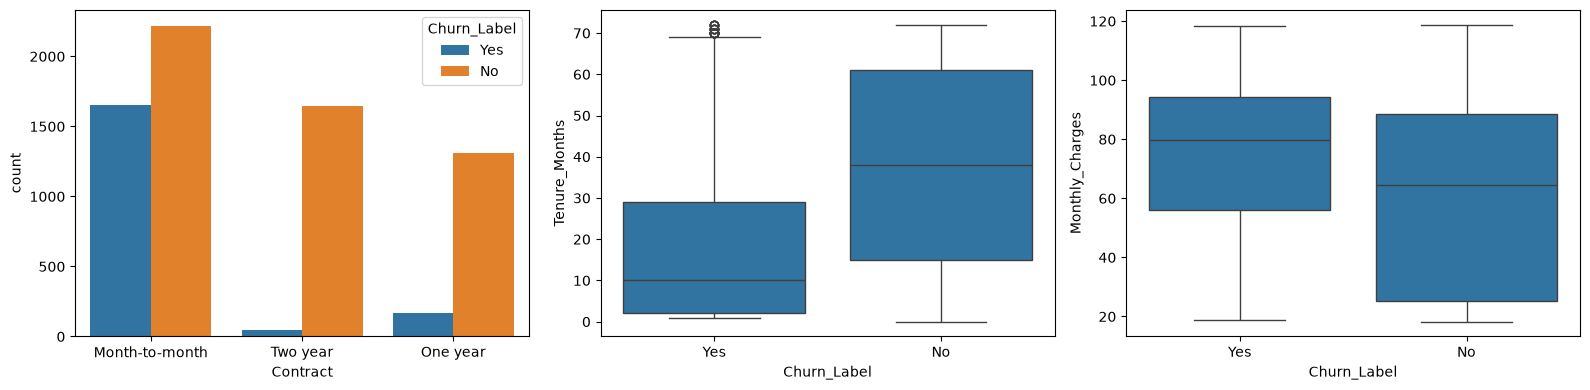

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="Contract", hue="Churn_Label", ax=axes[0])
sns.boxplot(data=df, x="Churn_Label", y="Tenure_Months", ax=axes[1])
sns.boxplot(data=df, x="Churn_Label", y="Monthly_Charges", ax=axes[2])
plt.tight_layout()
plt.show()

In [7]:
for col in ["Contract", "Internet_Service", "Payment_Method"]:
    print(df.groupby(col)["Churn_Value"].mean().round(3), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn_Value, dtype: float64 

Internet_Service
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn_Value, dtype: float64 

Payment_Method
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn_Value, dtype: float64 



- **Contract:** month-to-month customers churn at 42.7%, versus 2.8% for two-year contracts - a 15x gap.
- **Internet service:** fiber optic customers churn at 41.9%, more than double DSL (19.0%). Worth flagging as a possible pricing or quality issue.
- **Payment method:** electronic check users churn at 45.3%, versus 15-17% for automatic payments.

## 2. Choose the features

`Churn_Label`, `Churn_Score`, `CLTV` and `Churn_Reason` are only known once a
customer has churned, so keeping them would be straight-up leakage - the
model would score 0.9+ on almost everyone. The location columns are dropped
to avoid high-cardinality noise, and `CustomerID` because it carries no
information.

In [8]:
drop_cols = [
    "CustomerID", "Count", "Country", "State", "City", "Zip_Code",
    "Lat_Long", "Latitude", "Longitude",
    "Churn_Label", "Churn_Score", "CLTV", "Churn_Reason",
]
df_model = df.drop(columns=drop_cols)
df_model.to_csv(DATA / "telco_clean.csv", index=False)

# 22 rows are exact duplicates once the ID column is gone. Keeping them would
# put the same observation in both the train and the test split, so the
# modelling dataset drops them.
n_before = len(df_model)
df_modeling = df_model.drop_duplicates().reset_index(drop=True)
df_modeling.to_csv(DATA / "telco_modeling.csv", index=False)

print(f"telco_clean.csv    {n_before} rows (EDA output)")
print(f"telco_modeling.csv {len(df_modeling)} rows "
      f"({n_before - len(df_modeling)} exact duplicates removed)")

telco_clean.csv    7043 rows (EDA output)
telco_modeling.csv 7021 rows (22 exact duplicates removed)


## 3. Preprocessing

One `Pipeline` that does the imputing, scaling and one-hot encoding, fitted
on the training split only. The numeric scaler is not needed by the trees but
it keeps the columns on a comparable scale, which matters for the SHAP
values shown in the app.

In [9]:
# The modelling dataset is the deduplicated one - this is exactly what
# src/train.py reads.
df = pd.read_csv(DATA / "telco_modeling.csv")
df["Total_Charges"] = pd.to_numeric(df["Total_Charges"], errors="coerce")

X = df.drop(columns=["Churn_Value"])
y = df["Churn_Value"].to_numpy()

num_cols = ["Tenure_Months", "Monthly_Charges", "Total_Charges"]
cat_cols = [c for c in X.columns if c not in num_cols]
print("rows:", len(df))
print("Numeric:", num_cols)
print("Categorical:", len(cat_cols), "columns")

rows: 7021
Numeric: ['Tenure_Months', 'Monthly_Charges', 'Total_Charges']
Categorical: 16 columns


In [10]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print(X_train.shape, X_test.shape)
print("churn rate  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

(5616, 19) (1405, 19)
churn rate  train: 0.264  test: 0.265


## 4. Model selection

The test split is put aside and scored **once**, at the very end. The model
is chosen with 5-fold cross-validation over the training split alone.

The three models land within one standard error of each other, so the
one-standard-error rule applies: every candidate is within noise of the best,
and the tie is broken on the requirements of the app (fast exact SHAP
explanations, small artifact) rather than on a difference the data cannot
support.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print("scale_pos_weight:", round(scale_pos_weight, 2))

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced",
        random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=scale_pos_weight, eval_metric="logloss",
        random_state=SEED),
}
pipelines = {
    name: Pipeline([("prep", preprocessor), ("model", model)])
    for name, model in models.items()
}

scale_pos_weight: 2.78


In [13]:
cv_scores = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_scores[name] = (scores.mean(), scores.std())
    print(f"{name:22s} ROC-AUC {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression    ROC-AUC 0.8591 (+/- 0.0154)


Random Forest          ROC-AUC 0.8629 (+/- 0.0153)


XGBoost                ROC-AUC 0.8572 (+/- 0.0168)


In [14]:
best_name = max(cv_scores, key=lambda n: cv_scores[n][0])
best_mean, best_std = cv_scores[best_name]
cutoff = best_mean - best_std
feasible = [n for n in cv_scores if cv_scores[n][0] >= cutoff]
preference = ["XGBoost", "Random Forest", "Logistic Regression"]
selected = next(n for n in preference if n in feasible)

print(f"best            : {best_name} ({best_mean:.4f})")
print(f"1-SE cutoff     : {cutoff:.4f}")
print(f"within one SE   : {feasible}")
print(f"selected        : {selected}")

best            : Random Forest (0.8629)
1-SE cutoff     : 0.8476
within one SE   : ['Logistic Regression', 'Random Forest', 'XGBoost']
selected        : XGBoost


In [15]:
final_pipe = pipelines[selected]
final_pipe.fit(X_train, y_train)
print("fitted", selected, "on", len(X_train), "rows")

fitted XGBoost on 5616 rows


## 5. Calibrate the score

The model is class weighted so that recall is high, which means its raw
output is a **ranking score**, not a probability: on the test set it predicted
an average risk of 38% against a true churn rate of 26%.

A calibrator fitted on out-of-fold predictions fixes that. Both a sigmoid
(Platt) and an isotonic calibrator are tried, and the one with the better
cross-validated log loss wins.

In [16]:
oof = cross_val_predict(pipelines[selected], X_train, y_train, cv=cv,
                        method="predict_proba")[:, 1]
print("out-of-fold predictions:", oof.shape)

out-of-fold predictions: (5616,)


In [17]:
def fit_calibrator(method, p, y_):
    if method == "isotonic":
        est = IsotonicRegression(out_of_bounds="clip")
        est.fit(np.asarray(p, float), np.asarray(y_))
    else:
        est = LogisticRegression()
        est.fit(logit(p).reshape(-1, 1), np.asarray(y_))
    return est

calib_log_loss = {}
for method in ("isotonic", "sigmoid"):
    preds = np.zeros(len(y_train))
    for tr, te in cv.split(oof.reshape(-1, 1), y_train):
        est = fit_calibrator(method, oof[tr], y_train[tr])
        preds[te] = apply_calibrator(est, method, oof[te])
    calib_log_loss[method] = log_loss(y_train, np.clip(preds, 1e-9, 1 - 1e-9))
    print(f"{method:9s} CV log loss {calib_log_loss[method]:.4f}")

calib_method = min(calib_log_loss, key=calib_log_loss.get)
calibrator = fit_calibrator(calib_method, oof, y_train)
print("chosen:", calib_method)

isotonic  CV log loss 0.4206
sigmoid   CV log loss 0.4013
chosen: sigmoid


In [18]:
oof_calibrated = apply_calibrator(calibrator, calib_method, oof)
print(f"mean out-of-fold score   before calibration: {oof.mean():.3f}")
print(f"mean out-of-fold score   after  calibration: {oof_calibrated.mean():.3f}")
print(f"true churn rate on training data:            {y_train.mean():.3f}")

mean out-of-fold score   before calibration: 0.379
mean out-of-fold score   after  calibration: 0.264
true churn rate on training data:            0.264


## 6. Pick the operating point

Recall is what a retention team is measured on, so the threshold is chosen
on the training data as the most precise cut-off that still catches 80% of
the churners. It is then applied unchanged to the test split.

In [19]:
precision, recall, thresholds = precision_recall_curve(y_train, oof_calibrated)
precision, recall, thresholds = precision[:-1], recall[:-1], thresholds[:-1]

target_recall = 0.80
feasible = np.flatnonzero(recall >= target_recall)
best_precision = precision[feasible].max()
candidates = feasible[precision[feasible] >= best_precision - 1e-12]
idx = int(candidates[np.argmax(recall[candidates])])
threshold = float(thresholds[idx])

print(f"threshold      : {threshold:.3f}")
print(f"train precision: {precision[idx]:.3f}")
print(f"train recall   : {recall[idx]:.3f}")

threshold      : 0.294
train precision: 0.540
train recall   : 0.802


## 7. Evaluate on the test split - once

This is the only time the test split is touched.

In [20]:
test_raw = final_pipe.predict_proba(X_test)[:, 1]
test_prob = apply_calibrator(calibrator, calib_method, test_raw)
test_pred = test_prob >= threshold

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
test_metrics = {
    "roc_auc": roc_auc_score(y_test, test_raw),
    "pr_auc": average_precision_score(y_test, test_prob),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "accuracy": (test_pred == y_test).mean(),
    "brier": brier_score_loss(y_test, test_prob),
    "log_loss": log_loss(y_test, np.clip(test_prob, 1e-9, 1 - 1e-9)),
}
pd.Series(test_metrics).round(4).to_frame("value")

,value
roc_auc,0.8484
pr_auc,0.6562
precision,0.5106
recall,0.7742
f1,0.6154
accuracy,0.7438
brier,0.1355
log_loss,0.4084


In [21]:
print(f"confusion matrix   TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"mean predicted     {test_prob.mean():.3f}")
print(f"actual base rate   {y_test.mean():.3f}")
print(f"calibration gap    {test_prob.mean() - y_test.mean():+.3f}")

confusion matrix   TN=757  FP=276  FN=84  TP=288
mean predicted     0.266
actual base rate   0.265
calibration gap    +0.001


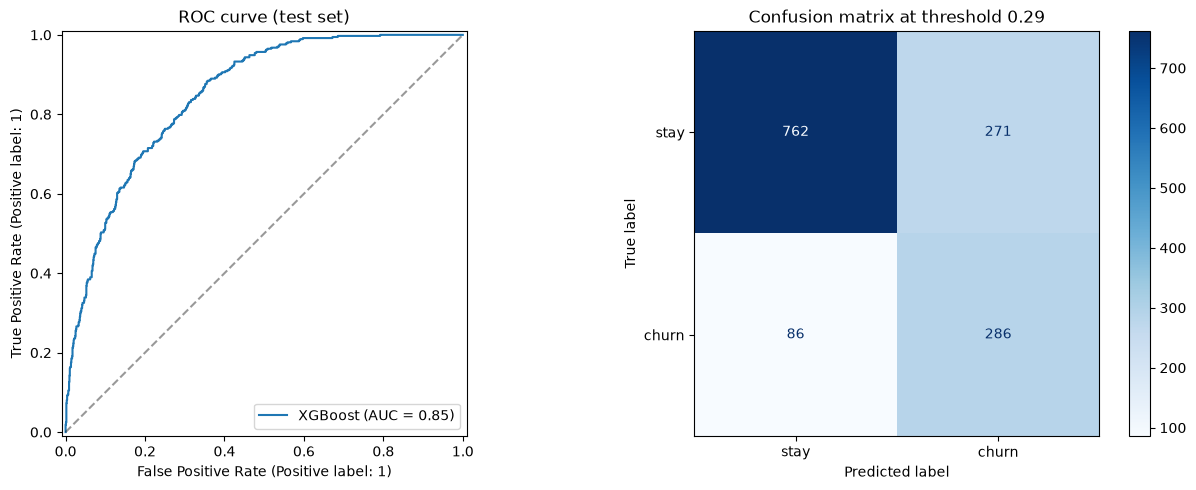

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_estimator(final_pipe, X_test, y_test, ax=axes[0], name=selected)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curve (test set)")
ConfusionMatrixDisplay.from_estimator(
    final_pipe, X_test, y_test, ax=axes[1], cmap="Blues", display_labels=["stay", "churn"])
axes[1].set_title(f"Confusion matrix at threshold {threshold:.2f}")
plt.tight_layout()
plt.show()

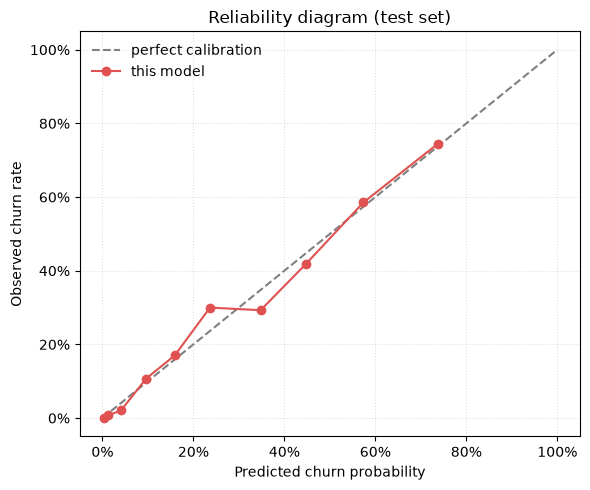

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

frac_pos, mean_pred = calibration_curve(y_test, test_prob, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.plot(mean_pred, frac_pos, "-o", color="#e05252", label="this model")
ax.set_xlabel("Predicted churn probability")
ax.set_ylabel("Observed churn rate")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Reliability diagram (test set)")
ax.grid(linestyle=":", alpha=0.4)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Explain the model with SHAP

The one-hot encoding turns 19 features into 46 columns, which makes the
SHAP output hard to read. The dummy columns are summed back into their
original feature so that every explanation has one row per feature.

In [24]:
explainer = shap.TreeExplainer(final_pipe.named_steps["model"])

prep = final_pipe.named_steps["prep"]
X_test_t = prep.transform(X_test)
if hasattr(X_test_t, "toarray"):
    X_test_t = X_test_t.toarray()
feature_names = [n.replace("num__", "").replace("cat__", "") for n in prep.get_feature_names_out()]
X_test_df = pd.DataFrame(X_test_t, columns=feature_names)

shap_values = explainer(X_test_df)
print("shap values:", shap_values.values.shape)

shap values: (1405, 46)


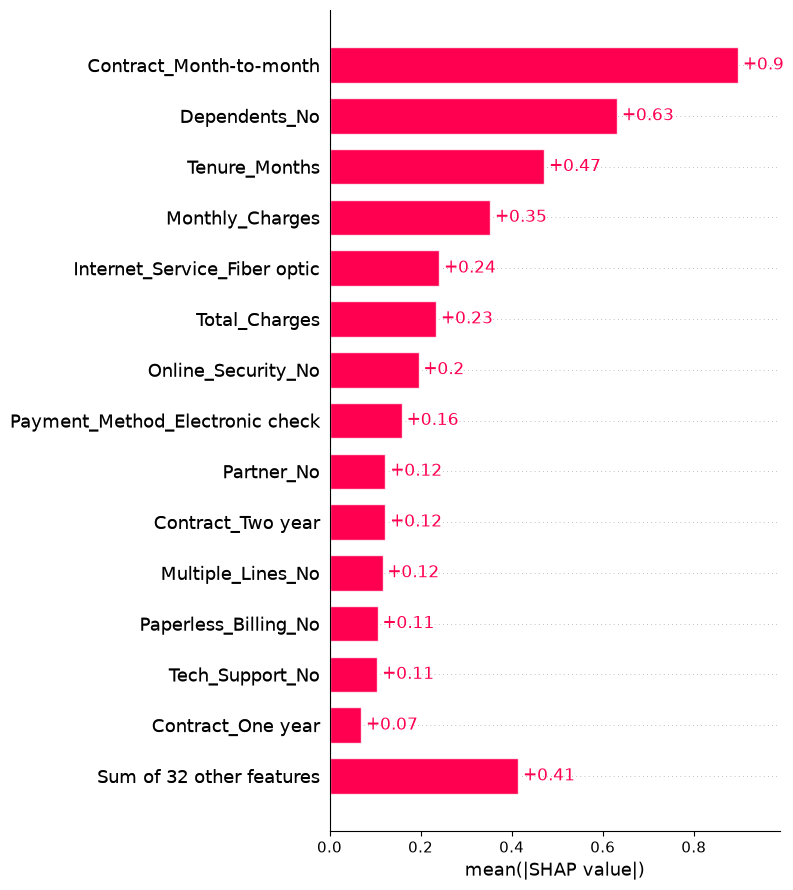

In [25]:
import os
os.makedirs(ROOT / "images", exist_ok=True)

shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig(ROOT / "images" / "shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

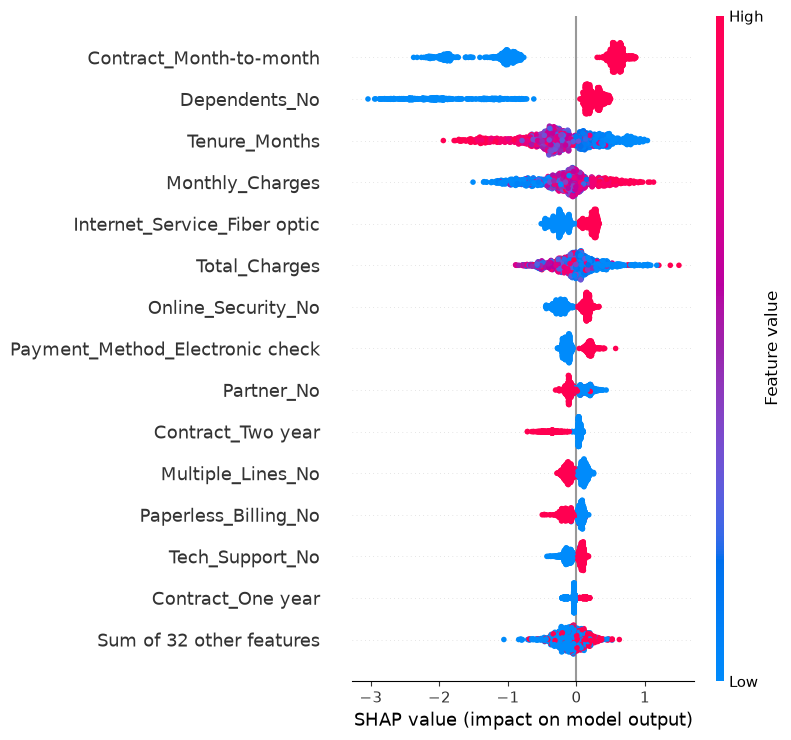

In [26]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig(ROOT / "images" / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
# The same aggregation the app uses, so the two never drift apart.
meta_like = {
    "feature_order": X.columns.tolist(),
    "num_cols": num_cols,
    "cat_cols": cat_cols,
}
idx = int(np.argmax(test_prob))          # highest-risk customer in the test set
print("calibrated churn probability:", round(test_prob[idx], 3))

row = X_test.iloc[idx].to_dict()
explanation = explain(explainer, final_pipe, meta_like, X_test.iloc[[idx]])
phi = explanation["feature_phi"]

labels = feature_labels(explanation["names"], row)
path = driver_path(phi, explanation["base_value"],
                   transform=lambda p: apply_calibrator(calibrator, calib_method, p))
for (indices, _), step in zip(path["segments"], path["steps"]):
    label = labels[indices[0]] if len(indices) == 1 else f"Other factors ({len(indices)})"
    print(f"  {label:42s} {step * 100:+6.2f} pp")

calibrated churn probability: 0.914
  Tenure = 1 months                          +14.50 pp
  Contract = Month-to-month                  +13.01 pp
  Monthly charges = $100.80                   +9.52 pp
  Total charges = $100.80                     +7.33 pp
  Internet Service = Fiber optic              +3.39 pp
  Dependents = No                             +2.84 pp
  Multiple Lines = Yes                        +2.48 pp
  Payment Method = Electronic check           +2.16 pp
  Online Security = No                        +1.70 pp
  Senior Citizen = Yes                        +1.46 pp
  Other factors (9)                           +3.01 pp


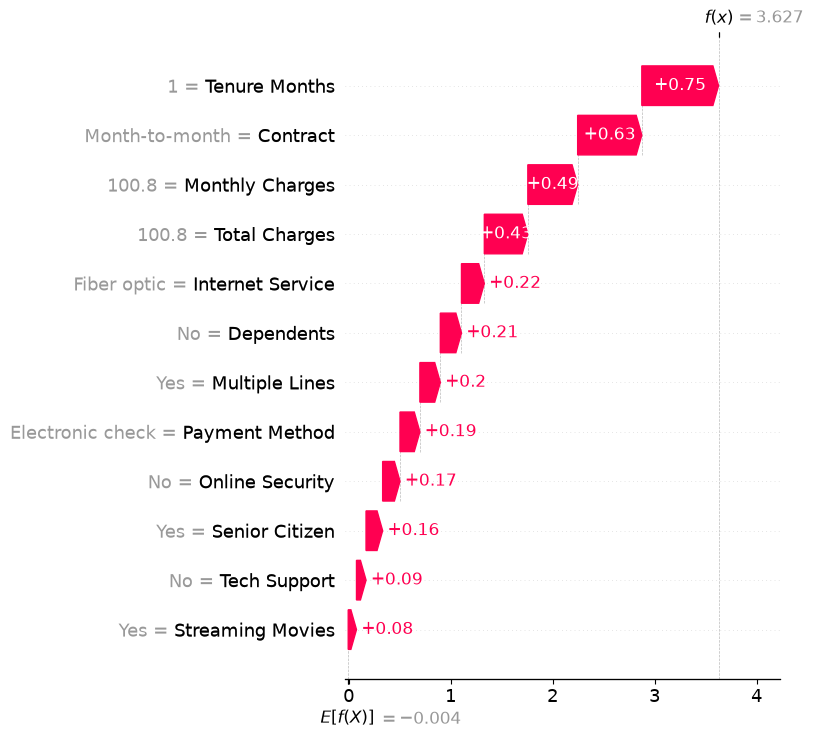

In [28]:
# Native SHAP waterfall in log-odds, aggregated to the original features
names = explanation["names"]
phi_by_name = explanation["phi_by_name"]
short = [n.replace("_", " ") for n in names]
values = [str(row[n]) for n in names]
order = np.argsort(-np.abs(phi))[:12]
aggregated = shap.Explanation(
    values=phi[order].reshape(1, -1),
    base_values=np.array([explanation["base_value"]]),
    data=np.array([values], dtype=object)[:, order],
    feature_names=[short[i] for i in order],
)
shap.plots.waterfall(aggregated[0], max_display=12, show=False)
plt.tight_layout()
plt.savefig(ROOT / "images" / "shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Reproduce it

Everything above is packaged into a single reproducible script that writes
the model, the calibrator and the metadata the app reads:

```bash
python src/train.py     # retrain
pytest tests            # check the artifacts and the app
streamlit run app.py    # serve
```